In [1]:

import platform
import sys

print("Python version:", sys.version)
print("Processor:", platform.machine())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
    print("CUDA available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch is not installed.")


Python version: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]
Processor: AMD64
PyTorch version: 2.14.1+cpu
MPS available: False
CUDA available: False


In [2]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: C:\Users\david\anaconda3\envs\cifar10\python.exe
Python version: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]


In [3]:

import sys
import torch
import torchvision

print("Python:", sys.version)
print("Python environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)]
Python environment: C:\Users\david\anaconda3\envs\cifar10\python.exe
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
MPS available: False



# IAI600 - CIFAR-10 Image Classification Project

## 1. Dataset Loading and Exploration

This project compares Multilayer Perceptron (MLP) and
Convolutional Neural Network (CNN) architectures
for image classification using the CIFAR-10 dataset.


In [4]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torchvision.datasets import CIFAR10

# Use Apple GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 classes
classes = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Classes:", classes)


Device: cpu
Training images: 50000
Test images: 10000
Image shape: torch.Size([3, 32, 32])
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']



## 1.2 Dataset Visualization

In this section, we visualize sample images from
the CIFAR-10 dataset to understand its structure,
image characteristics, and class labels.


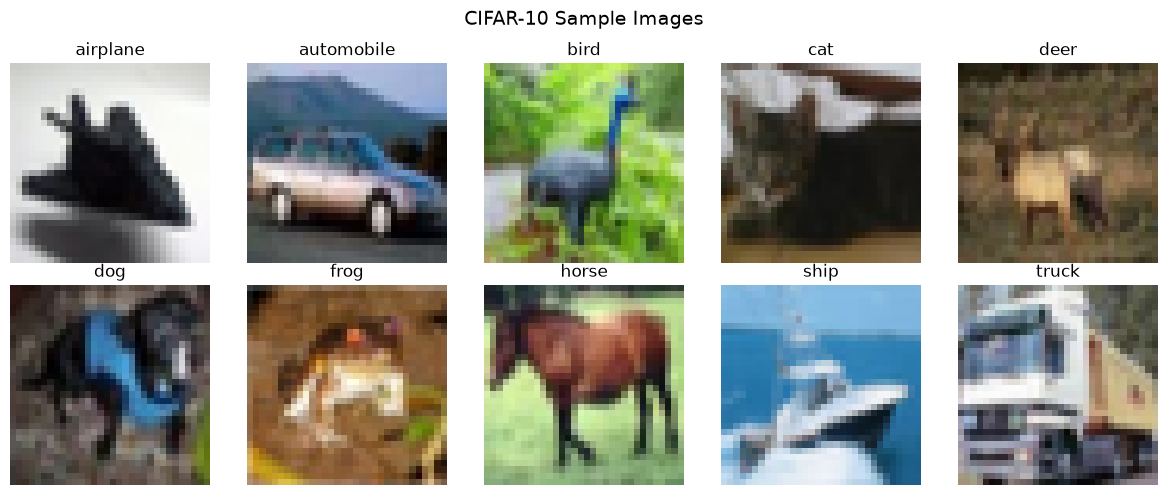

In [5]:

import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
classes = train_dataset.classes

# Display one example from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_idx in range(10):

    # Find the first image belonging to this class
    image_idx = train_dataset.targets.index(class_idx)

    # Get image and label
    image, label = train_dataset[image_idx]

    # Convert from [C, H, W] to [H, W, C]
    image = image.permute(1, 2, 0).numpy()

    # Display image
    ax = axes[class_idx // 5, class_idx % 5]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=14)
plt.tight_layout()
plt.show()



## 1.3 Class Distribution Analysis

This section examines the number of images in each
CIFAR-10 class to determine whether the dataset
is balanced across all categories.


Class Distribution:
---------------------------------------------
airplane     | Train:  5000 | Test:  1000
automobile   | Train:  5000 | Test:  1000
bird         | Train:  5000 | Test:  1000
cat          | Train:  5000 | Test:  1000
deer         | Train:  5000 | Test:  1000
dog          | Train:  5000 | Test:  1000
frog         | Train:  5000 | Test:  1000
horse        | Train:  5000 | Test:  1000
ship         | Train:  5000 | Test:  1000
truck        | Train:  5000 | Test:  1000


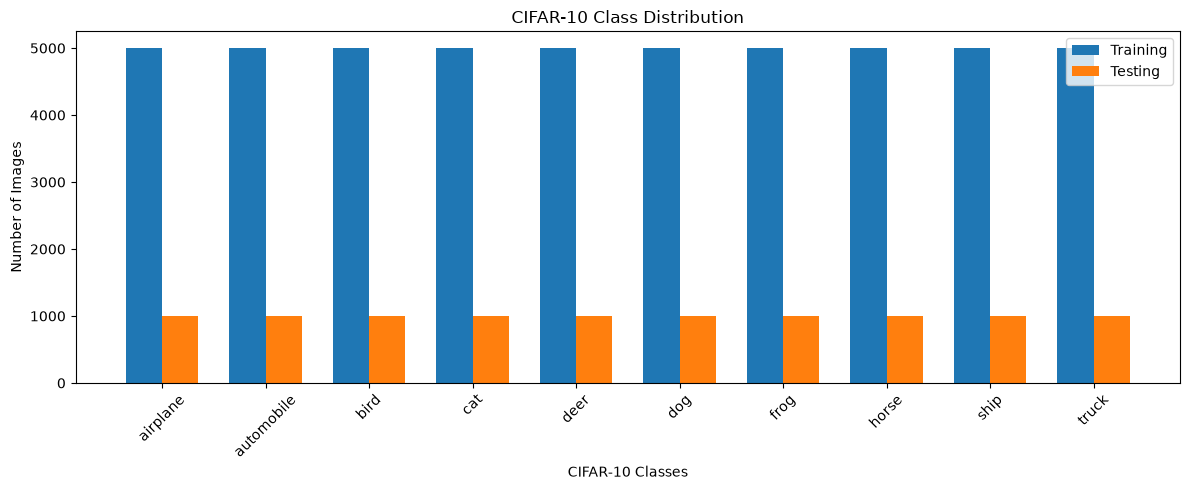

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# Count images for each class
train_counts = np.bincount(
    train_dataset.targets, minlength=10
)

test_counts = np.bincount(
    test_dataset.targets, minlength=10
)

# Display the number of images
print("Class Distribution:")
print("-" * 45)

for i, class_name in enumerate(classes):
    print(
        f"{class_name:12s} | "
        f"Train: {train_counts[i]:5d} | "
        f"Test: {test_counts[i]:5d}"
    )

# Create bar chart
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width/2,
    train_counts,
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    test_counts,
    width,
    label="Testing"
)

plt.xlabel("CIFAR-10 Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(x, classes, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 1.4 Stratified Train/Validation Split

The original CIFAR-10 training dataset contains
50,000 images.

We split this dataset into 90% training and
10% validation data using stratified sampling.

Stratification preserves the class distribution,
ensuring that all 10 classes are equally represented.

A fixed random seed (42) is used for reproducibility.
The original test set remains unchanged.


In [7]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np

# Original labels from CIFAR-10 training dataset
labels = np.array(train_dataset.targets)

# Indices for all 50,000 training images
indices = np.arange(len(train_dataset))

# Stratified split: 90% training, 10% validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=labels
)

# Create training and validation subsets
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

# Verify dataset sizes
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

# Verify class distribution
train_labels = labels[train_indices]
val_labels = labels[val_indices]

print("\nClass Distribution After Split:")
print("-" * 45)

for i, class_name in enumerate(classes):
    train_count = np.sum(train_labels == i)
    val_count = np.sum(val_labels == i)

    print(
        f"{class_name:12s} | "
        f"Train: {train_count:5d} | "
        f"Validation: {val_count:4d}"
    )


Training samples: 45000
Validation samples: 5000
Test samples: 10000

Class Distribution After Split:
---------------------------------------------
airplane     | Train:  4500 | Validation:  500
automobile   | Train:  4500 | Validation:  500
bird         | Train:  4500 | Validation:  500
cat          | Train:  4500 | Validation:  500
deer         | Train:  4500 | Validation:  500
dog          | Train:  4500 | Validation:  500
frog         | Train:  4500 | Validation:  500
horse        | Train:  4500 | Validation:  500
ship         | Train:  4500 | Validation:  500
truck        | Train:  4500 | Validation:  500



## 1.5 Data Normalization

We compute channel-wise mean and standard deviation
using only the training subset.

The same normalization parameters will be applied
to training, validation, and test images to avoid
data leakage and ensure consistent preprocessing.


In [8]:

from torch.utils.data import DataLoader

# Temporary DataLoader for computing statistics
stats_loader = DataLoader(
    train_subset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images, labels_batch in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sum_sq += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / total_pixels
std = torch.sqrt(
    channel_sum_sq / total_pixels - mean ** 2
)

print("Training mean:", mean)
print("Training std:", std)


Training mean: tensor([0.4911, 0.4821, 0.4464])
Training std: tensor([0.2469, 0.2434, 0.2616])


In [9]:

from torchvision import transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

# Normalization transform
normalized_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

# Load the existing datasets with normalization
normalized_train_full = CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=normalized_transform
)

normalized_test = CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=normalized_transform
)

# Reuse exactly the same indices
train_final = Subset(normalized_train_full, train_indices)
val_final = Subset(normalized_train_full, val_indices)
test_final = normalized_test

print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Testing:", len(test_final))


Training: 45000
Validation: 5000
Testing: 10000


In [10]:

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Image dtype:", images.dtype)


Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])
Image dtype: torch.float32



## 1.6 Final Preprocessing Verification

This section verifies that the normalized training
dataset has approximately zero channel-wise mean
and unit standard deviation.

It also verifies that the training, validation,
and test datasets contain the expected samples.


In [11]:

# Verify normalization using the complete training set
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images_batch, _ in train_loader:
    channel_sum += images_batch.sum(dim=(0, 2, 3))
    channel_sum_sq += (images_batch ** 2).sum(dim=(0, 2, 3))
    total_pixels += images_batch.shape[0] * 32 * 32

verified_mean = channel_sum / total_pixels
verified_std = torch.sqrt(
    channel_sum_sq / total_pixels - verified_mean ** 2
)

print("Normalized training mean:", verified_mean)
print("Normalized training std:", verified_std)

print("\nDataset sizes:")
print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Test:", len(test_final))

# Final checks
assert len(train_final) == 45000
assert len(val_final) == 5000
assert len(test_final) == 10000

assert set(train_indices).isdisjoint(set(val_indices))

assert torch.allclose(
    verified_mean, torch.zeros(3), atol=1e-4
)

assert torch.allclose(
    verified_std, torch.ones(3), atol=1e-4
)

print("\nAll preprocessing checks passed!")


Normalized training mean: tensor([ 1.4047e-07,  5.4762e-07, -4.7975e-08])
Normalized training std: tensor([1.0000, 1.0000, 1.0000])

Dataset sizes:
Training: 45000
Validation: 5000
Test: 10000

All preprocessing checks passed!



## 1.7 Reproducibility and Group Handoff

We save the exact training and validation indices
and normalization parameters to ensure that the
MLP and CNN models use identical data partitions
and preprocessing settings.


In [12]:

import json
from pathlib import Path

# Create a folder for shared configuration files
config_dir = Path("config")
config_dir.mkdir(exist_ok=True)

# Save exact dataset indices
np.savez(
    config_dir / "split_indices.npz",
    train_indices=train_indices,
    val_indices=val_indices
)

# Save preprocessing parameters
config = {
    "dataset": "CIFAR-10",
    "random_state": 42,
    "training_samples": 45000,
    "validation_samples": 5000,
    "test_samples": 10000,
    "batch_size": BATCH_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "classes": classes
}

with open(
    config_dir / "preprocessing_config.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

print("Configuration files saved successfully!")
print("Files:")
print(config_dir / "split_indices.npz")
print(config_dir / "preprocessing_config.json")


Configuration files saved successfully!
Files:
config\split_indices.npz
config\preprocessing_config.json



## 1.8 Configuration Verification

This section verifies that the saved preprocessing
configuration and dataset indices can be reloaded
correctly for reproducible experiments.


In [13]:

import json
import numpy as np

# Load saved dataset indices
saved_indices = np.load("config/split_indices.npz")

saved_train = saved_indices["train_indices"]
saved_val = saved_indices["val_indices"]

# Load saved preprocessing configuration
with open("config/preprocessing_config.json", "r") as file:
    saved_config = json.load(file)

# Verify saved values
assert np.array_equal(saved_train, train_indices)
assert np.array_equal(saved_val, val_indices)

assert len(saved_train) == 45000
assert len(saved_val) == 5000

assert np.allclose(saved_config["mean"], mean.numpy())
assert np.allclose(saved_config["std"], std.numpy())

print("Training indices:", len(saved_train))
print("Validation indices:", len(saved_val))
print("Saved mean:", saved_config["mean"])
print("Saved std:", saved_config["std"])
print("Batch size:", saved_config["batch_size"])

print("\nAll configuration checks passed!")


Training indices: 45000
Validation indices: 5000
Saved mean: [0.4911373257637024, 0.4821110665798187, 0.44644901156425476]
Saved std: [0.246869295835495, 0.24343018233776093, 0.261603444814682]
Batch size: 64

All configuration checks passed!


In [14]:

from data_preparation import get_cifar10_loaders

# Load datasets using the shared module
train_loader_shared, val_loader_shared, test_loader_shared = (
    get_cifar10_loaders()
)

# Check dataset sizes
print("Training:", len(train_loader_shared.dataset))
print("Validation:", len(val_loader_shared.dataset))
print("Testing:", len(test_loader_shared.dataset))

# Check one batch
images, labels = next(iter(train_loader_shared))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("\nShared data preparation module works!")


Training: 45000
Validation: 5000
Testing: 10000

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])

Shared data preparation module works!


In [15]:
import torch
from torch import nn
from copy import deepcopy

torch.manual_seed(42)

train_loader = train_loader_shared
val_loader = val_loader_shared

# each image has 32 × 32 × 3 = 3072 values
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3072, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)

best_accuracy = -1
best_weights = deepcopy(mlp.state_dict())

for epoch in range(10):

    # train the model using batches of images
    mlp.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = mlp(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Check validation accuracy without updating the model
    mlp.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = mlp(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    train_accuracy = train_correct / train_total
    val_accuracy = val_correct / val_total

    # Keep a copy whenever validation accuracy improves
    if val_accuracy > best_accuracy:
        best_accuracy = val_accuracy
        best_weights = deepcopy(mlp.state_dict())

    print(
        f"Epoch {epoch + 1}: "
        f"Training = {train_accuracy:.2%}, "
        f"Validation = {val_accuracy:.2%}"
    )

# Restore and save the best model
mlp.load_state_dict(best_weights)
mlp.eval()
torch.save(mlp.state_dict(), "mlp_weights.pth")

print(f"\nBest validation accuracy: {best_accuracy:.2%}")

Epoch 1: Training = 41.05%, Validation = 44.92%
Epoch 2: Training = 47.92%, Validation = 46.76%
Epoch 3: Training = 50.78%, Validation = 48.04%
Epoch 4: Training = 53.16%, Validation = 49.48%
Epoch 5: Training = 54.70%, Validation = 49.98%
Epoch 6: Training = 56.34%, Validation = 49.26%
Epoch 7: Training = 57.86%, Validation = 51.34%
Epoch 8: Training = 59.04%, Validation = 49.84%
Epoch 9: Training = 60.30%, Validation = 50.42%
Epoch 10: Training = 61.30%, Validation = 50.46%

Best validation accuracy: 51.34%


# CNN model

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim

class CIFAR10_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 32 x 16 x 16

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 64 x 8 x 8

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)   # 128 x 4 x 4
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = CIFAR10_CNN().to(device)
print(cnn_model)
print("Using device:", device)

CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)
Using device: cpu


In [17]:
device = torch.device("cpu")
cnn_model = cnn_model.to(device)

print("Using device:", device)

Using device: cpu


In [18]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

num_epochs = 10

cnn_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    # Training
    cnn_model.train()
    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_total += loss.item() * batch_size
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_total / train_total
    train_acc = 100.0 * train_correct / train_total

    # Validation
    cnn_model.eval()
    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_total += loss.item() * batch_size
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_total / val_total
    val_acc = 100.0 * val_correct / val_total

    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["train_accuracy"].append(train_acc)
    cnn_history["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_acc:.2f}%"
    )

Epoch [1/10] Train Loss: 1.4216 | Train Accuracy: 48.55% | Validation Loss: 1.1138 | Validation Accuracy: 60.28%
Epoch [2/10] Train Loss: 0.9995 | Train Accuracy: 64.80% | Validation Loss: 0.8847 | Validation Accuracy: 68.88%
Epoch [3/10] Train Loss: 0.8192 | Train Accuracy: 71.27% | Validation Loss: 0.7635 | Validation Accuracy: 73.48%
Epoch [4/10] Train Loss: 0.7034 | Train Accuracy: 75.34% | Validation Loss: 0.7593 | Validation Accuracy: 73.36%
Epoch [5/10] Train Loss: 0.6137 | Train Accuracy: 78.50% | Validation Loss: 0.7629 | Validation Accuracy: 73.76%
Epoch [6/10] Train Loss: 0.5383 | Train Accuracy: 81.14% | Validation Loss: 0.7120 | Validation Accuracy: 75.68%
Epoch [7/10] Train Loss: 0.4657 | Train Accuracy: 83.73% | Validation Loss: 0.7077 | Validation Accuracy: 76.06%
Epoch [8/10] Train Loss: 0.4093 | Train Accuracy: 85.33% | Validation Loss: 0.7453 | Validation Accuracy: 76.08%
Epoch [9/10] Train Loss: 0.3545 | Train Accuracy: 87.38% | Validation Loss: 0.7478 | Validation 

In [19]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    cnn_model.parameters(),
    lr=0.0003,
    weight_decay=0.005
)

print("Optimizer configured successfully.")

Optimizer configured successfully.


In [20]:

import importlib
import data_preparation

importlib.reload(data_preparation)

train_loader, val_loader, test_loader = (
    data_preparation.get_cifar10_loaders(
        project_dir=".",
        download=False
    )
)

print("Training:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))


Training: 45000
Validation: 5000
Test: 10000


In [21]:
import sys
import importlib.util

print("Python location:", sys.executable)
print("PyTorch installed:", importlib.util.find_spec("torch") is not None)

Python location: C:\Users\david\anaconda3\envs\cifar10\python.exe
PyTorch installed: True


In [22]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [23]:
import torch
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


In [24]:
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("All libraries are ready.")

All libraries are ready.


In [25]:
num_epochs = 25
patience = 5

best_val_loss = float("inf")
best_val_accuracy = 0.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

model_path = "cnn_cifar10_regularized.pth"

for epoch in range(num_epochs):

    # Training phase
    cnn_model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # Validation phase
    cnn_model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100.0 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}% | "
        f"Validation Loss: {val_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.2f}%"
    )

    # Save the best model by validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        epochs_without_improvement = 0

        torch.save(cnn_model.state_dict(), model_path)
        print("  Best model saved.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping after epoch {epoch + 1}.")
        break

print("\nTraining finished.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best loss: {best_val_accuracy:.2f}%")
print("Best model saved to:", model_path)

cnn_model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)
cnn_model.eval()

Epoch [1/25] Train Loss: 0.1816 | Train Accuracy: 93.58% | Validation Loss: 0.8399 | Validation Accuracy: 77.90%
  Best model saved.
Epoch [2/25] Train Loss: 0.1427 | Train Accuracy: 95.07% | Validation Loss: 0.8625 | Validation Accuracy: 77.84%
Epoch [3/25] Train Loss: 0.1218 | Train Accuracy: 95.74% | Validation Loss: 0.9227 | Validation Accuracy: 77.94%
Epoch [4/25] Train Loss: 0.1076 | Train Accuracy: 96.26% | Validation Loss: 0.9618 | Validation Accuracy: 78.04%
Epoch [5/25] Train Loss: 0.0938 | Train Accuracy: 96.72% | Validation Loss: 0.9675 | Validation Accuracy: 78.24%
Epoch [6/25] Train Loss: 0.0854 | Train Accuracy: 97.14% | Validation Loss: 1.0175 | Validation Accuracy: 77.50%
Early stopping after epoch 6.

Training finished.
Best validation loss: 0.8399
Validation accuracy at best loss: 77.90%
Best model saved to: cnn_cifar10_regularized.pth


CIFAR10_CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)

In [26]:
model_path = "cnn_cifar10_regularized.pth"

best_model = CIFAR10_CNN().to(device)
best_model.load_state_dict(
    torch.load(model_path, map_location=device)
)
best_model.eval()

#  test set evaluation
test_correct = 0
test_total = 0
test_loss_sum = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        loss = criterion(outputs, labels)

        test_loss_sum += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = 100.0 * test_correct / test_total
test_loss = test_loss_sum / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Correct predictions: {test_correct}/{test_total}")

Test Loss: 0.9042
Test Accuracy: 77.39%
Correct predictions: 7739/10000


In [27]:

from pathlib import Path

print("Current folder:", Path.cwd())

print("\nRequired files:")
files = [
    "data_preparation.py",
    "config/preprocessing_config.json",
    "config/split_indices.npz",
    "mlp_weights.pth",
    "cnn_cifar10_regularized.pth"
]

for file in files:
    status = "FOUND" if Path(file).is_file() else "MISSING"
    print(f"{file}: {status}")


Current folder: C:\Users\david\OneDrive\Documents\GitHub\CIFAR10-Image-Classification

Required files:
data_preparation.py: FOUND
config/preprocessing_config.json: FOUND
config/split_indices.npz: FOUND
mlp_weights.pth: FOUND
cnn_cifar10_regularized.pth: FOUND


In [28]:

from pathlib import Path

print("Saved model files:")

for file in Path(".").iterdir():
    if file.is_file() and file.name.endswith((".pth", ".pt")):
        print(repr(file.name))


Saved model files:
'cnn_cifar10_regularized.pth'
'mlp_weights.pth'


In [29]:

import torch
from torch import nn
from sklearn.metrics import (
    accuracy_score,
    classification_report
)
from data_preparation import get_cifar10_loaders

# Load the test dataset
_, _, test_loader = get_cifar10_loaders(
    project_dir=".",
    download=False
)

# Recreate the MLP architecture
mlp_eval = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3072, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

# Load the trained weights
mlp_eval.load_state_dict(
    torch.load(
        "mlp_weights.pth",
        map_location="cpu",
        weights_only=True
    )
)

mlp_eval.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = mlp_eval(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.tolist())

classes = [
    "airplane", "automobile", "bird", "cat",
    "deer", "dog", "frog", "horse",
    "ship", "truck"
]

print("MLP Test Accuracy:",
      f"{accuracy_score(y_true, y_pred)*100:.2f}%")

print("\nMLP Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    digits=4,
    zero_division=0
))


MLP Test Accuracy: 50.20%

MLP Classification Report:
              precision    recall  f1-score   support

    airplane     0.6054    0.5200    0.5594      1000
  automobile     0.6254    0.5710    0.5970      1000
        bird     0.3828    0.4620    0.4187      1000
         cat     0.3596    0.1870    0.2461      1000
        deer     0.4939    0.3260    0.3928      1000
         dog     0.4005    0.4490    0.4234      1000
        frog     0.4980    0.6100    0.5483      1000
       horse     0.5345    0.6270    0.5771      1000
        ship     0.5738    0.7000    0.6306      1000
       truck     0.5154    0.5680    0.5404      1000

    accuracy                         0.5020     10000
   macro avg     0.4989    0.5020    0.4934     10000
weighted avg     0.4989    0.5020    0.4934     10000



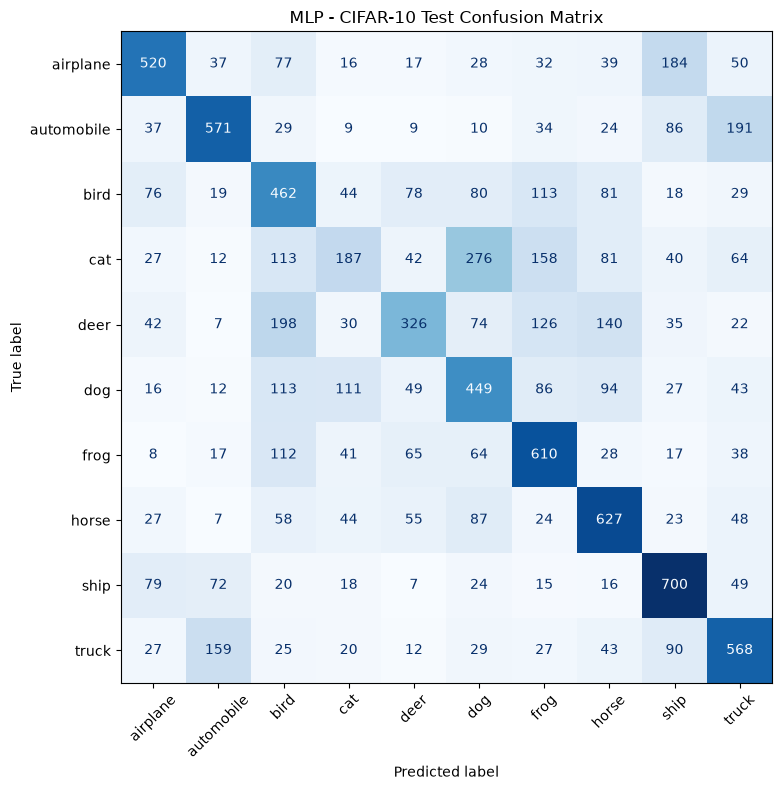

In [30]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

# Create folder for report figures
Path("results").mkdir(exist_ok=True)

# Plot MLP confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=classes,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)

plt.title("MLP - CIFAR-10 Test Confusion Matrix")
plt.tight_layout()

# Save figure for the report
plt.savefig(
    "results/MLP_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [31]:

print("CNN model available:", "cnn_model" in globals())

if "history" in globals():
    print("CNN training epochs:", len(history["train_loss"]))
else:
    print("AdamW training history not available")

if "cnn_model" in globals():
    print(
        "Model device:",
        next(cnn_model.parameters()).device
    )


CNN model available: True
CNN training epochs: 6
Model device: cpu


In [32]:

import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Ensure CNN training has been completed
if "cnn_model" not in globals():
    raise RuntimeError("CNN model is not available.")

if (
    "history" not in globals()
    or len(history["train_loss"]) == 0
):
    raise RuntimeError(
        "Run the CNN training before evaluation."
    )

# Evaluate the trained CNN
cnn_model.eval()

model_device = next(cnn_model.parameters()).device

cnn_y_true = []
cnn_y_pred = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(model_device)

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        cnn_y_true.extend(labels.cpu().tolist())
        cnn_y_pred.extend(predictions.cpu().tolist())

print("CNN Test Accuracy:",
      f"{accuracy_score(cnn_y_true, cnn_y_pred)*100:.2f}%")

print("\nCNN Classification Report:")
print(classification_report(
    cnn_y_true,
    cnn_y_pred,
    target_names=classes,
    digits=4,
    zero_division=0
))

# Save our trained CNN weights
torch.save(
    cnn_model.state_dict(),
    "cnn_macos_last_epoch.pth"
)

print("\nCNN model weights saved!")


CNN Test Accuracy: 77.39%

CNN Classification Report:
              precision    recall  f1-score   support

    airplane     0.8093    0.8190    0.8141      1000
  automobile     0.8658    0.8970    0.8811      1000
        bird     0.7743    0.6210    0.6892      1000
         cat     0.5931    0.5860    0.5895      1000
        deer     0.7299    0.7270    0.7285      1000
         dog     0.6282    0.7250    0.6732      1000
        frog     0.8307    0.8390    0.8348      1000
       horse     0.8090    0.8260    0.8174      1000
        ship     0.8637    0.8810    0.8723      1000
       truck     0.8512    0.8180    0.8343      1000

    accuracy                         0.7739     10000
   macro avg     0.7755    0.7739    0.7734     10000
weighted avg     0.7755    0.7739    0.7734     10000


CNN model weights saved!


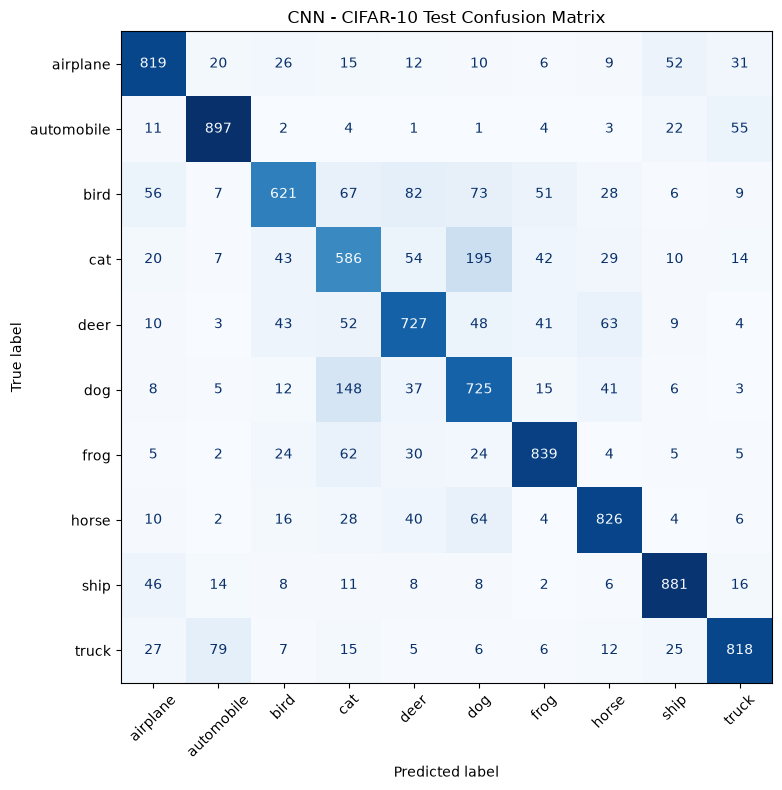

In [33]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

# Create results folder
Path("results").mkdir(exist_ok=True)

# CNN Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    cnn_y_true,
    cnn_y_pred,
    display_labels=classes,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
    colorbar=False
)

plt.title("CNN - CIFAR-10 Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "results/CNN_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
